# 13.4 USDA Food Database

## Mục đích
Mục đích chính của việc phân tích Cơ sở dữ liệu Thực phẩm USDA là để khám phá chi tiết hàm lượng dinh dưỡng của các loại thực phẩm được Bộ Nông nghiệp Hoa Kỳ công bố, qua đó xây dựng một hiểu biết sâu sắc về thành phần dinh dưỡng của chúng. Để đạt được điều này, dữ liệu cần được tái cấu trúc thành một định dạng bảng cho phép phân tích dinh dưỡng hiệu quả theo các nhóm thực phẩm lớn (food groups). Cuối cùng, phân tích này nhằm đánh giá các mối tương quan giữa các thành phần dinh dưỡng khác nhau, chẳng hạn như mối liên hệ giữa hàm lượng protein, chất béo (lipid) và năng lượng (energy), nhằm đưa ra những kết luận toàn diện về đặc tính dinh dưỡng của các nhóm thực phẩm.

## Mục tiêu
Mục tiêu tổng quát là chuyển đổi dữ liệu thô, phức tạp thành thông tin dinh dưỡng có giá trị để hỗ trợ nghiên cứu và khuyến nghị sức khỏe:

+ Khám phá Dinh dưỡng: Khám phá hàm lượng dinh dưỡng của các loại thực phẩm được USDA công bố để xác định các nguồn cung cấp chất dinh dưỡng cụ thể (ví dụ: thực phẩm giàu Protein, thấp Năng lượng).

+ Cấu trúc hóa Dữ liệu: Tạo cấu trúc dữ liệu phẳng (DataFrame) cho phép phân tích dinh dưỡng hiệu quả theo các nhóm thực phẩm lớn (food groups).

+ Đánh giá Tương quan: Đánh giá các mối tương quan giữa các chất dinh dưỡng (như protein, chất béo, năng lượng) để hiểu được cách các thành phần dinh dưỡng liên kết với nhau trong thực phẩm.

## Input
Dữ liệu thô JSON phức tạp của USDA Food Database. Sau khi xử lý, đầu vào được chuẩn hóa thành DataFrame Pandas (ndata) với các biến chính là group và description (tên chất dinh dưỡng), cùng với các giá trị hàm lượng.

## Output
các thông tin có ý nghĩa, bao gồm các giá trị Trung bình/Trung vị để xác định hàm lượng điển hình, các bảng xếp hạng thực phẩm có giá trị dinh dưỡng cực đại, các chỉ số Tương quan giữa các chất dinh dưỡng, và các Tỷ lệ Dinh dưỡng tổng hợp (như $E/P$) để đánh giá chất lượng và hỗ trợ cho các khuyến nghị dinh dưỡng.

Bộ Nông nghiệp Hoa Kỳ (USDA) cung cấp cơ sở dữ liệu thông tin dinh dưỡng trong thực phẩm. Lập trình viên Ashley Williams đã tạo ra một phiên bản của cơ sở dữ liệu này ở định dạng JSON.
File data có dạng:

In [1267]:
[
    {
        "id": 1008,
        "description": "Cheese, caraway",
        "tags": [],
        "manufacturer": "",
        "group": "Dairy and Egg Products",
        "portions": [
            {
                "amount": 1,
                "unit": "oz",
                "grams": 28.35
            }
        ],
        "nutrients": [
            {
                "value": 25.18,
                "units": "g",
                "description": "Protein",
                "group": "Composition"
            },
            ...
        ]
    },
    ...
]

[{'id': 1008,
  'description': 'Cheese, caraway',
  'tags': [],
  'manufacturer': '',
  'group': 'Dairy and Egg Products',
  'portions': [{'amount': 1, 'unit': 'oz', 'grams': 28.35}],
  'nutrients': [{'value': 25.18,
    'units': 'g',
    'description': 'Protein',
    'group': 'Composition'},
   Ellipsis]},
 Ellipsis]

Từ điển thực phẩm chứa các thuộc tính cơ bản như id, description, manufacturer, và group (nhóm thực phẩm).

Có hai trường là danh sách lồng nhau (phân cấp dữ liệu):

+ portions chứa chi tiết khẩu phần ăn.

+ nutrients là một Danh sách các Từ điển con, chứa thông tin dinh dưỡng chi tiết. Mỗi Từ điển con trong danh sách mô tả một chất dinh dưỡng duy nhất.

Các khóa trong từ điển chất dinh dưỡng bao gồm value (hàm lượng), units (đơn vị), description (tên chất dinh dưỡng), và group (nhóm dinh dưỡng).

Cấu trúc nhiều lớp này yêu cầu kỹ thuật làm phẳng dữ liệu để phân tích bảng

## 13.4.1 Set up

### Import thư viện

In [1268]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns


### Tạo thư mục images

In [1269]:
import os

# 1. Định nghĩa đường dẫn và tên thư mục
folder_name = "images" 

# 2. Tạo thư mục
os.makedirs(folder_name, exist_ok=True) 

## 13.4.2 Xử lý dữ liệu

### Load database
Load database dưới dạng file JSON

In [1270]:
import json
db = json.load(open("../datasets/usda_food/database.json"))
print("Số phần tử:", len(db))

Số phần tử: 6636


## Tái cấu trúc dữ liệu
Quá trình tái cấu trúc dữ liệu (data restructuring) là bước nền tảng và quan trọng nhất trong việc phân tích bộ dữ liệu USDA Food Database. Nó cần thiết vì dữ liệu ban đầu nằm ở định dạng JSON phân cấp (nested JSON), khiến các thuộc tính của chất dinh dưỡng (như value và units) bị lồng sâu bên trong mỗi bản ghi thực phẩm.

Mục tiêu của tái cấu trúc là chuyển dữ liệu từ cấu trúc phân cấp sang cấu trúc phẳng (flat structure), dễ dàng truy vấn và phân tích bằng Pandas.

### Trích Xuất và Làm Phẳng

Tạo DataFrame con từ dữ liệu gốc, đặt tên là info.
Lấy danh sách thông tin thực phẩm bao gồm tên thực phẩm, nhóm, ID và nhà sản xuất:

In [1271]:
info_keys = ["description", "group", "id", "manufacturer"]
info = pd.DataFrame(db, columns=info_keys)
info.head()

,description,group,id,manufacturer
0,"Cheese, caraway",Dairy and Egg Products,1008,
1,"Cheese, cheddar",Dairy and Egg Products,1009,
2,"Cheese, edam",Dairy and Egg Products,1018,
3,"Cheese, feta",Dairy and Egg Products,1019,
4,"Cheese, mozzarella, part skim milk",Dairy and Egg Products,1028,


Chuyển đổi từng danh sách chất dinh dưỡng của thực phẩm thành một DataFrame.

Gắn nhãn: một cột id duy nhất của thực phẩm được lấy ra và gán cho tất cả các hàng trong DataFrame nhỏ (fnuts["id"] = rec["id"]). Việc này là tối quan trọng để duy trì mối liên kết giữa chất dinh dưỡng chi tiết và thực phẩm gốc. Sau đó, chúng có thể được nối với nhau bằng hàm concat:

In [1272]:
nutrients = []
for rec in db:
    fnuts = pd.DataFrame(rec["nutrients"])
    fnuts["id"] = rec["id"]
    nutrients.append(fnuts)
nutrients = pd.concat(nutrients, ignore_index=True)

nutrients

,value,units,description,group,id
0,25.180,g,Protein,Composition,1008
1,29.200,g,Total lipid (fat),Composition,1008
2,3.060,g,"Carbohydrate, by difference",Composition,1008
3,3.280,g,Ash,Other,1008
4,376.000,kcal,Energy,Energy,1008
...,...,...,...,...,...
389350,0.000,mcg,"Vitamin B-12, added",Vitamins,43546
389351,0.000,mg,Cholesterol,Other,43546
389352,0.072,g,"Fatty acids, total saturated",Other,43546
389353,0.028,g,"Fatty acids, total monounsaturated",Other,43546


### Xử lý dữ liệu trùng

In [1273]:
# Kiểm tra dữ liệu trùng
print("Số dữ liệu bị trùng:", nutrients.duplicated().sum())

Số dữ liệu bị trùng: 14179


In [1274]:
# Tiến hành xử lý bằng drop_duplicates()
nutrients = nutrients.drop_duplicates()

# kiểm tra lại
print("Số dữ liệu bị trùng:", nutrients.duplicated().sum())

Số dữ liệu bị trùng: 0


Vì cả 2 DataFrame đều chứa cột "description" và "group", nên sẽ đổi tên để dễ dàng phân biệt.

In [1275]:
col_mapping = {"description" : "food", "group" : "fgroup"}
# Đổi tên cột
info = info.rename(columns=col_mapping, copy=False)

info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6636 entries, 0 to 6635
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   food          6636 non-null   object
 1   fgroup        6636 non-null   object
 2   id            6636 non-null   int64 
 3   manufacturer  5195 non-null   object
dtypes: int64(1), object(3)
memory usage: 207.5+ KB


In [1276]:
# Trên DataFrame gốc
col_mapping = {"description" : "nutrient", "group" : "nutgroup"}
# Đổi tên cột
nutrients = nutrients.rename(columns=col_mapping, copy=False)

nutrients.info()


<class 'pandas.core.frame.DataFrame'>
Index: 375176 entries, 0 to 389354
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   value     375176 non-null  float64
 1   units     375176 non-null  object 
 2   nutrient  375176 non-null  object 
 3   nutgroup  375176 non-null  object 
 4   id        375176 non-null  int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 17.2+ MB


### Tổng Hợp và Chuẩn Hóa
Tiến hành merge dữ liệu từ 2 DataFrame thông qua cột id:

In [1277]:
ndata = pd.merge(nutrients, info, on="id")

ndata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375176 entries, 0 to 375175
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   value         375176 non-null  float64
 1   units         375176 non-null  object 
 2   nutrient      375176 non-null  object 
 3   nutgroup      375176 non-null  object 
 4   id            375176 non-null  int64  
 5   food          375176 non-null  object 
 6   fgroup        375176 non-null  object 
 7   manufacturer  293054 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 22.9+ MB


In [1278]:
ndata.head(10)

,value,units,nutrient,nutgroup,id,food,fgroup,manufacturer
0,25.18,g,Protein,Composition,1008,"Cheese, caraway",Dairy and Egg Products,
1,29.20,g,Total lipid (fat),Composition,1008,"Cheese, caraway",Dairy and Egg Products,
2,3.06,g,"Carbohydrate, by difference",Composition,1008,"Cheese, caraway",Dairy and Egg Products,
3,3.28,g,Ash,Other,1008,"Cheese, caraway",Dairy and Egg Products,
4,376.00,kcal,Energy,Energy,1008,"Cheese, caraway",Dairy and Egg Products,
5,39.28,g,Water,Composition,1008,"Cheese, caraway",Dairy and Egg Products,
6,1573.00,kJ,Energy,Energy,1008,"Cheese, caraway",Dairy and Egg Products,
7,0.00,g,"Fiber, total dietary",Composition,1008,"Cheese, caraway",Dairy and Egg Products,
8,673.00,mg,"Calcium, Ca",Elements,1008,"Cheese, caraway",Dairy and Egg Products,
9,0.64,mg,"Iron, Fe",Elements,1008,"Cheese, caraway",Dairy and Egg Products,


## 13.4.3 Phân tích dữ liệu
### Câu hỏi nghiên cứu
#### Phân tích mô tả
Trong phân này chúng ta sẽ tìm hiểu về các câu hỏi sau:
+ Trung bình năng lượng (kcal) của từng nhóm thực phẩm là bao nhiêu? 
+ Loại thực phẩm nào chứa protein cao nhất trong nhóm “Dairy and Egg Products”?
+ Nhóm nào có độ đa dạng dinh dưỡng cao nhất (nhiều loại chất khác nhau)?

#### Trung bình năng lượng (kcal) của từng nhóm thực phẩm là bao nhiêu?

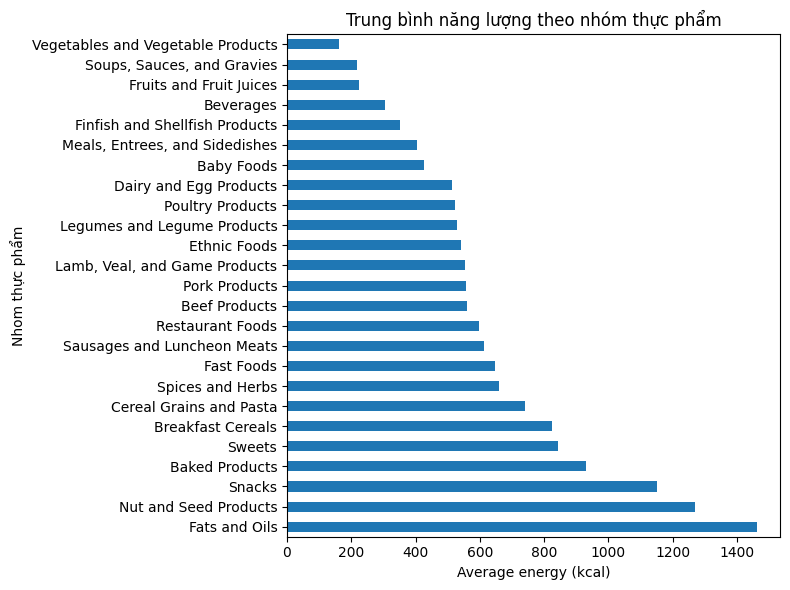

In [1279]:
ndata[ndata['nutrient']=="Energy"].groupby('fgroup')['value'].mean().sort_values(ascending=False).plot(kind='barh', figsize=(8,6))
plt.xlabel("Average energy (kcal)")
plt.ylabel("Nhom thực phẩm")
plt.title("Trung bình năng lượng theo nhóm thực phẩm")
plt.tight_layout()
plt.savefig("images/average_energy_per_food_group.png")

Nhóm giàu năng lượng nhất:

+ Chất béo và Dầu (Fats and Oils) có mức năng lượng trung bình cao nhất, vượt trội so với tất cả các nhóm khác (hơn 1400 kcal). Điều này là do chất béo là chất cung cấp nhiều năng lượng nhất.

+ Theo sau là các nhóm như Các loại hạt (Nut and Seed Products), Đồ ăn vặt (Snacks), Đồ ngọt (Sweets) và Bánh nướng (Baked Products). Đây đều là những nhóm thực phẩm thường chứa nhiều chất béo và đường.

Nhóm ít năng lượng nhất:

+ Rau và các sản phẩm từ rau (Vegetables and Vegetable Products) có mức năng lượng trung bình thấp nhất.

+ Các nhóm khác cũng có ít năng lượng bao gồm Súp và nước sốt (Soups, Sauces, and Gravies), Trái cây và nước ép (Fruits and Fruit Juices), và Đồ uống (Beverages). Các loại thực phẩm này thường chứa nhiều nước và chất xơ.

> → Điều này sát với thực tế vì ăn thực phẩm có nhiều chất béo hay đồ ngọt sẽ nhanh no hơn các loại từ rau hay đồ uống.

#### Loại thực phẩm nào chứa protein cao nhất trong nhóm “Dairy and Egg Products”?


C:\Users\biedu\AppData\Local\Temp\ipykernel_11704\4227063141.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




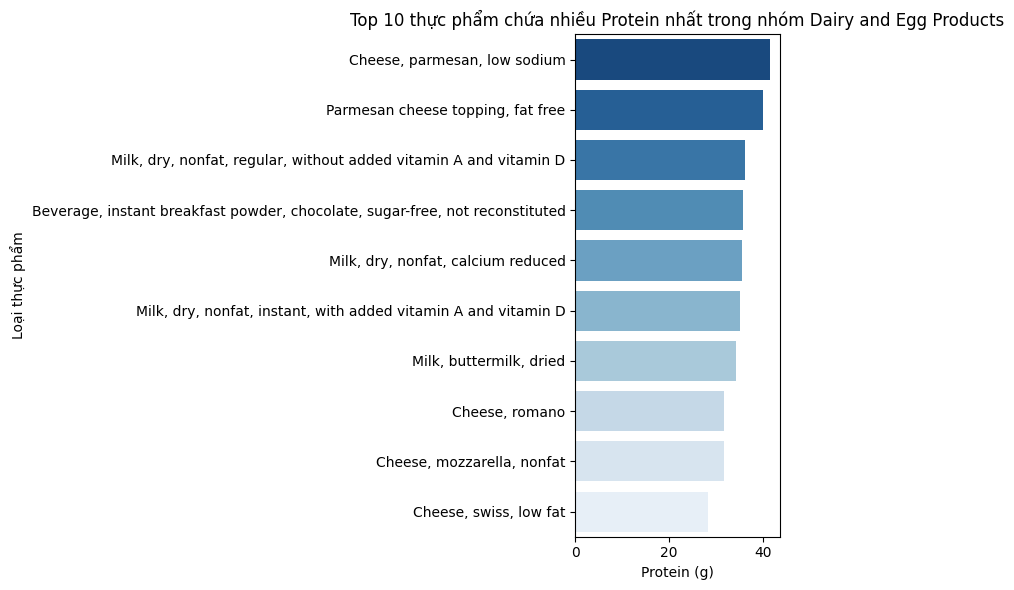

In [1280]:
protein_data = ndata[(ndata['fgroup']=="Dairy and Egg Products") & (ndata['nutrient']=="Protein")]
top_10 = protein_data.sort_values(by='value', ascending=False).head(10)
plt.figure(figsize=(8, 6))
sns.barplot(data=top_10, y='food', x='value', palette='Blues_r')
plt.xlabel('Protein (g)')
plt.ylabel('Loại thực phẩm')
plt.title('Top 10 thực phẩm chứa nhiều Protein nhất trong nhóm Dairy and Egg Products')
plt.tight_layout()
plt.show()

Hàm lượng protein dao động khoảng từ 30–40g/100g, trong đó “Cheese, parmesan, low sodium” có giá trị cao nhất, vượt trội hơn các sản phẩm khác trong cùng nhóm.

→ Các sản phẩm chế biến từ sữa, đặc biệt là phô mai và sữa bột, là nguồn cung cấp protein phong phú, phù hợp cho chế độ ăn cần nhiều đạm như người luyện tập thể thao hoặc cần bổ sung năng lượng cao.

#### Nhóm nào có độ đa dạng dinh dưỡng cao nhất (nhiều loại chất khác nhau)?

In [1281]:
# Đếm số lượng loại chất dinh dưỡng (nutrient) khác nhau trong từng nhóm thực phẩm (fgroup)
diversity = ndata.groupby('fgroup')['nutrient'].nunique().reset_index()

# Đổi tên cột cho dễ hiểu
diversity.columns = ['Food Group', 'Unique Nutrients Count']

# Sắp xếp giảm dần để nhóm đa dạng nhất nằm trên cùng
diversity_sorted = diversity.sort_values(by='Unique Nutrients Count', ascending=False)

# Lấy nhóm có độ đa dạng dinh dưỡng cao nhất
most_diverse = diversity_sorted.iloc[0]
most_diverse

Food Group                Vegetables and Vegetable Products
Unique Nutrients Count                                   94
Name: 24, dtype: object

C:\Users\biedu\AppData\Local\Temp\ipykernel_11704\4169661671.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




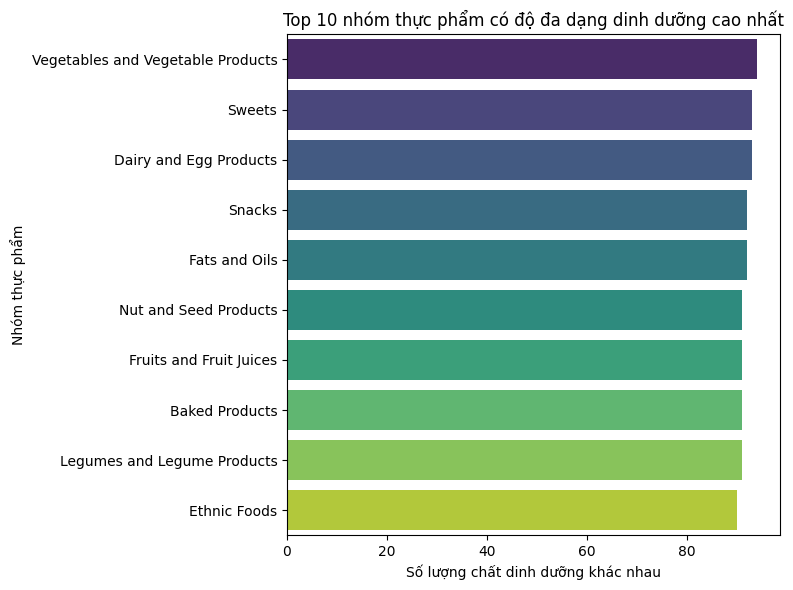

In [1282]:
# Biểu đồ cột cho 10 nhóm thực phẩm có độ đa dạng dinh dưỡng cao nhất
plt.figure(figsize=(8, 6))
sns.barplot(data=diversity_sorted.head(10), 
            y='Food Group', 
            x='Unique Nutrients Count', 
            palette='viridis')

plt.title('Top 10 nhóm thực phẩm có độ đa dạng dinh dưỡng cao nhất')
plt.xlabel('Số lượng chất dinh dưỡng khác nhau')
plt.ylabel('Nhóm thực phẩm')
plt.tight_layout()
plt.show()

→ Nhìn chung, các nhóm thực phẩm nguồn gốc thực vật (như rau, đậu, trái cây) có xu hướng đa dạng hơn về loại chất dinh dưỡng so với các nhóm thực phẩm có nguồn gốc động vật hoặc tinh chế.

Điều này cho thấy tầm quan trọng của việc kết hợp nhiều nhóm thực phẩm khác nhau trong khẩu phần ăn để đảm bảo cung cấp đầy đủ dưỡng chất cho cơ thể.

→ Hãy ăn nhiều rau vì nó cung cấp rất nhiều chất dinh dưỡng cho cơ thể.

### Câu hỏi nghiên cứu
#### Phân tích so sánh
Trong phân này chúng ta sẽ tìm hiểu về các câu hỏi sau:
+ So sánh hàm lượng protein và lipid (chất béo) giữa nhóm “Meat” và “Dairy”?
+ Tỷ lệ Energy-to-Protein khác biệt thế nào giữa nhóm “Grains” và “Vegetables”?

#### So sánh hàm lượng protein và lipid (chất béo) giữa nhóm “Meat” và “Dairy”?
Mục đích: Giúp chúng ta hiểu rõ bản chất dinh dưỡng, tối ưu hóa khẩu phần ăn, và ứng dụng trong nghiên cứu hoặc sản xuất thực phẩm

In [1283]:
## Lọc dữ liệu theo nhóm và chất dinh dưỡng

# Lọc dữ liệu cho hai nhóm thực phẩm Meat và Dairy
df_meat = ndata[ndata['fgroup'].str.contains('Meat', case=False, na=False)]
df_dairy = ndata[ndata['fgroup'].str.contains('Dairy', case=False, na=False)]

# Lọc riêng 2 loại chất cần so sánh: Protein và Total lipid (fat)
nutrients = ['Protein', 'Total lipid (fat)']
df_meat = df_meat[df_meat['nutrient'].isin(nutrients)]
df_dairy = df_dairy[df_dairy['nutrient'].isin(nutrients)]

In [1284]:
## Tính trung bình hàm lượng dinh dưỡng trong từng nhóm

# Tính trung bình hàm lượng protein và lipid cho mỗi nhóm
mean_meat = df_meat.groupby('nutrient')['value'].mean()
mean_dairy = df_dairy.groupby('nutrient')['value'].mean()

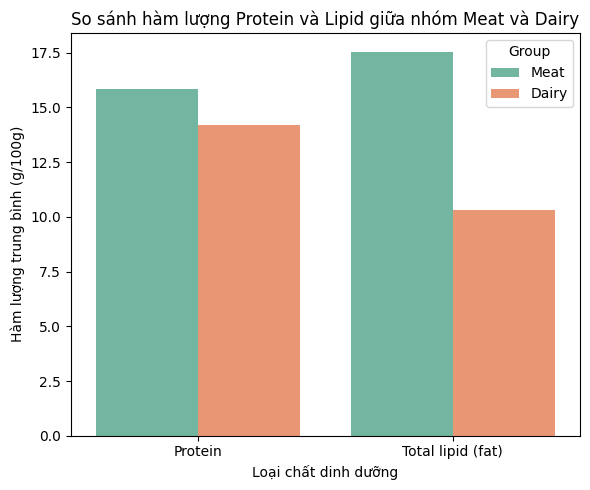

In [1285]:
## So sánh trực quan bằng biểu đồ

# Gộp hai nhóm vào một DataFrame để vẽ
compare_df = pd.DataFrame({
    'Meat': mean_meat,
    'Dairy': mean_dairy
}).T  # chuyển vị để nutrient thành cột

compare_df = compare_df.reset_index().melt(id_vars='index', var_name='Nutrient', value_name='Value')
compare_df.rename(columns={'index': 'Group'}, inplace=True)

# Vẽ biểu đồ
plt.figure(figsize=(6, 5))
sns.barplot(data=compare_df, x='Nutrient', y='Value', hue='Group', palette='Set2')
plt.title('So sánh hàm lượng Protein và Lipid giữa nhóm Meat và Dairy')
plt.xlabel('Loại chất dinh dưỡng')
plt.ylabel('Hàm lượng trung bình (g/100g)')
plt.tight_layout()
plt.show()

Nhóm Meat có hàm lượng dinh dưỡng cao hơn ở cả hai chỉ tiêu. Trung bình, nhóm Meat (thịt) có hàm lượng Protein và Lipid (chất béo) cao hơn nhóm Dairy (sữa và sản phẩm từ sữa). Cụ thể, hàm lượng Protein của Meat (~16 g/100g) nhỉnh hơn Dairy (~14 g/100g), cho thấy thịt là nguồn cung cấp đạm dồi dào hơn.

Sự khác biệt rõ hơn ở hàm lượng Lipid khi mức Lipid trung bình của Meat (~17.5 g/100g) gần gấp rưỡi so với Dairy (~10 g/100g). Điều này cho thấy thịt, đặc biệt là các loại thịt đỏ hoặc thịt mỡ, có tỷ lệ chất béo cao hơn đáng kể so với sản phẩm từ sữa.

Ý nghĩa dinh dưỡng:

+ Thịt phù hợp cho chế độ ăn cần nhiều năng lượng và protein, chẳng hạn như cho người luyện tập thể thao hoặc phục hồi cơ bắp.

+ Sữa và sản phẩm từ sữa lại có tỷ lệ đạm – béo cân đối hơn, phù hợp với chế độ ăn duy trì sức khỏe và bổ sung khoáng chất (như canxi).

→ Việc lựa chọn nhóm thực phẩm nào phụ thuộc vào mục tiêu dinh dưỡng cá nhân – tăng cơ, giảm béo hay cân bằng năng lượng.

#### Tỷ lệ Energy-to-Protein khác biệt thế nào giữa nhóm “Grains” và “Vegetables”?
Tỷ lệ Energy-to-Protein (E/P ratio) cho biết một loại thực phẩm cung cấp bao nhiêu năng lượng (kcal) cho mỗi gram protein mà nó chứa. Qua đó đánh giá cân đối giữa năng lượng và protein trong thực phẩm, xây dựng chế độ ăn hợp lý và khoa học hơn 


Công thức tính tỷ lệ **Energy-to-Protein (E/P)** được biểu diễn như sau:

$$
E/P\ ratio = \frac{Energy\ (kcal)}{Protein\ (g)}
$$



Vì trong ndata, mỗi hàng chỉ chứa một loại chất dinh dưỡng cho một món ăn, nhưng ở đây ta lại cần đến 2 dạng dinh dưỡng để phân tích, nên ở đây ta sẽ dùng pivot_table giúp gom dữ liệu đúng cấu trúc, tự động xử lý trùng lặp và tính trung bình để tính toán.

C:\Users\biedu\AppData\Local\Temp\ipykernel_11704\1713532405.py:30: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




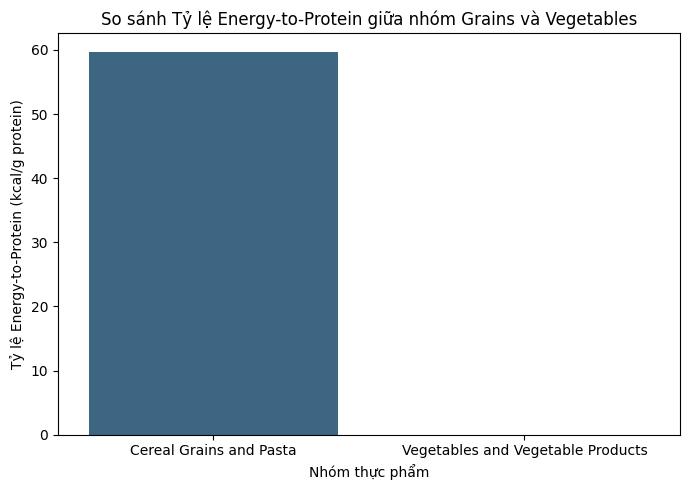

In [1286]:
### Lọc dữ liệu chỉ lấy hai nhóm thực phẩm: Grains và Vegetables
ndata_subset = ndata[ndata['fgroup'].str.contains('Grain|Vegetable', case=False, na=False)]

### Lọc hai loại chất cần phân tích: Energy và Protein
ndata_subset = ndata_subset[ndata_subset['nutrient'].isin(['Energy', 'Protein'])]

### Chuẩn hóa năng lượng về kcal (nếu đơn vị là kJ)
ndata_subset.loc[ndata_subset['units'] == 'kJ', 'value'] = ndata_subset['value'] / 4.184
ndata_subset.loc[ndata_subset['units'] == 'kJ', 'units'] = 'kcal'

### Dùng pivot_table để gom giá trị Energy và Protein thành 2 cột
pivot_ndata = ndata_subset.pivot_table(
    index=['food', 'fgroup'],   
    columns='nutrient',          
    values='value',           
    aggfunc='mean'    
).reset_index()

### Loại bỏ dòng bị thiếu dữ liệu
pivot_ndata = pivot_ndata.dropna(subset=['Energy', 'Protein'])

### Tính tỷ lệ Energy-to-Protein
pivot_ndata['Energy_to_Protein'] = pivot_ndata['Energy'] / pivot_ndata['Protein']

### Tính trung bình theo nhóm thực phẩm
ratio_by_group = pivot_ndata.groupby('fgroup')['Energy_to_Protein'].mean().reset_index()

### Vẽ biểu đồ so sánh
plt.figure(figsize=(7, 5))
sns.barplot(data=ratio_by_group, x='fgroup', y='Energy_to_Protein', palette='viridis')

plt.title('So sánh Tỷ lệ Energy-to-Protein giữa nhóm Grains và Vegetables')
plt.xlabel('Nhóm thực phẩm')
plt.ylabel('Tỷ lệ Energy-to-Protein (kcal/g protein)')
plt.tight_layout()
plt.show()


Nhóm “Cereal Grains and Pasta” có tỷ lệ Energy-to-Protein rất cao: Tỷ lệ E/P xấp xỉ 60 kcal/g protein, cho thấy đây là nhóm thực phẩm cung cấp nhiều năng lượng trên mỗi gram protein.

→ Điều này phản ánh rằng ngũ cốc chứa hàm lượng tinh bột cao, trong khi lượng protein tương đối thấp. Nói cách khác, phần lớn năng lượng từ nhóm này đến từ carbohydrate, không phải protein.

Ngược lại, Nhóm “Vegetables and Vegetable Products” có tỷ lệ Energy-to-Protein cực thấp: Tỷ lệ gần bằng 0 — nghĩa là lượng năng lượng rất thấp so với lượng protein.

→ Điều này phù hợp với đặc trưng của rau củ: nhiều nước, ít năng lượng, giàu chất xơ và vi chất, nhưng chỉ chứa lượng protein nhỏ. Vì vậy, rau củ thường không phải nguồn cung cấp năng lượng chính, mà đóng vai trò bổ sung vitamin, khoáng và cân bằng khẩu phần ăn.

### Câu hỏi nghiên cứu
#### Phân tích tương quan
Trong phân này chúng ta sẽ tìm hiểu về các câu hỏi sau:
+ Có mối tương quan nào giữa năng lượng (Energy) và hàm lượng chất béo (Fat)?
+ Nhóm thực phẩm nào có năng lượng cao nhưng protein thấp (chất “rỗng”)?
+ Các loại thực phẩm giàu “Water” có xu hướng ít năng lượng hơn không?

#### Có mối tương quan nào giữa năng lượng (Energy) và hàm lượng chất béo (Fat)?
Kiểm tra xem khi thực phẩm chứa nhiều chất béo (Total lipid – fat) thì năng lượng (Energy) có tăng tương ứng hay không.

Giá trị 4.184 xuất phát từ mối quan hệ giữa đơn vị năng lượng kilojoule (kJ) và kilocalorie (kcal).

Công thức chuẩn quốc tế là:

$$
1\ \text{kcal} = 4.184\ \text{kJ}
$$

$$
1\ \text{kJ} = 0.239\ \text{kcal}
$$

Hệ số tương quan giữa Energy và Fat: 0.768


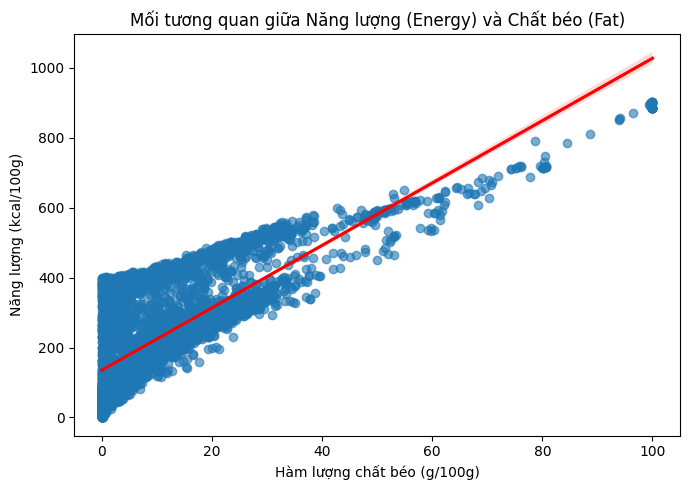

In [1287]:
# Lọc dữ liệu chỉ lấy Energy và Total lipid (fat)
ndata_corr = ndata[ndata['nutrient'].isin(['Energy', 'Total lipid (fat)'])]

# Chuẩn hóa năng lượng về kcal
ndata_corr.loc[ndata_corr['units'] == 'kJ', 'value'] = ndata_corr['value'] / 4.184
ndata_corr.loc[ndata_corr['units'] == 'kJ', 'units'] = 'kcal'

# Tạo bảng pivot để Energy và Fat nằm cùng hàng
pivot_corr = ndata_corr.pivot_table(
    index=['food', 'fgroup'],
    columns='nutrient',
    values='value',
    aggfunc='mean'
).reset_index()

# Loại bỏ các dòng thiếu dữ liệu
pivot_corr = pivot_corr.dropna(subset=['Energy', 'Total lipid (fat)'])

# Tính hệ số tương quan Pearson
corr_value = pivot_corr['Energy'].corr(pivot_corr['Total lipid (fat)'])
print(f"Hệ số tương quan giữa Energy và Fat: {corr_value:.3f}")

# Vẽ biểu đồ scatter thể hiện mối tương quan
plt.figure(figsize=(7, 5))
sns.regplot(
    data=pivot_corr,
    x='Total lipid (fat)',
    y='Energy',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)
plt.title('Mối tương quan giữa Năng lượng (Energy) và Chất béo (Fat)')
plt.xlabel('Hàm lượng chất béo (g/100g)')
plt.ylabel('Năng lượng (kcal/100g)')
plt.tight_layout()
plt.show()

Mối quan hệ tuyến tính thuận rất rõ ràng: Đường hồi quy màu đỏ cho thấy khi hàm lượng chất béo tăng, năng lượng của thực phẩm cũng tăng theo. Các điểm dữ liệu phân bố khá sát đường hồi quy → biểu hiện một mối tương quan thuận mạnh giữa hai biến.

Điều này hoàn toàn hợp lý về mặt sinh học và dinh dưỡng, vì 1 gram chất béo cung cấp khoảng 9 kcal,
trong khi 1 gram protein hoặc carbohydrate chỉ cung cấp khoảng 4 kcal.

Nhiều loại thực phẩm có năng lượng rất cao chủ yếu do chứa nhiều chất béo: Ở khu vực bên phải biểu đồ (Fat > 60g/100g), năng lượng có thể vượt quá 900 kcal/100g, cho thấy đó là các loại thực phẩm giàu chất béo như dầu, bơ, phô mai đậm đặc, hoặc các loại hạt.

Các nhóm thực phẩm ít béo cũng ít năng lượng: Ở khu vực Fat < 10g/100g, năng lượng thường < 200 kcal/100g — điển hình là các thực phẩm như rau củ, sữa gầy, thịt nạc hoặc ngũ cốc ít dầu.

→ Có mối tương quan tuyến tính mạnh và dương giữa năng lượng và chất béo. Nói cách khác, chất béo là yếu tố đóng góp lớn nhất vào giá trị năng lượng của thực phẩm.

#### Nhóm thực phẩm nào có năng lượng cao nhưng protein thấp (chất “rỗng”)?
Xem thực phẩm cung cấp nhiều năng lượng (Energy) nhưng ít protein (Protein) → dinh dưỡng kém chất lượng.

C:\Users\biedu\AppData\Local\Temp\ipykernel_11704\3771190465.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




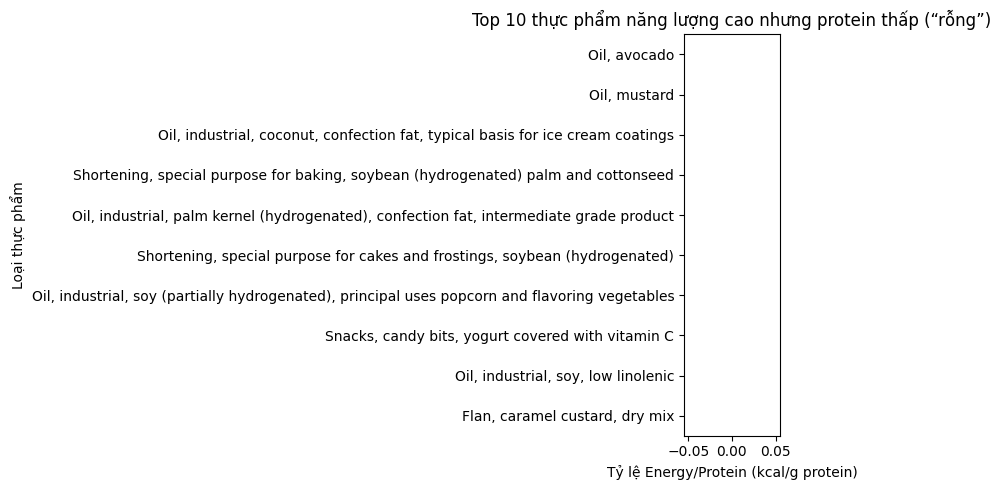

In [1288]:
ndata_nutri = ndata[ndata['nutrient'].isin(['Energy', 'Protein'])]

# Tạo bảng pivot gồm Energy và Protein
pivot_nutri = ndata_nutri.pivot_table(
    index=['food', 'fgroup'],
    columns='nutrient',
    values='value',
    aggfunc='mean'
).reset_index()

# Loại bỏ dòng thiếu dữ liệu
pivot_nutri = pivot_nutri.dropna(subset=['Energy', 'Protein'])

# Chuẩn hóa đơn vị năng lượng về kcal nếu có cả kJ
if 'units' in ndata.columns:
    if (ndata.loc[ndata['nutrient'] == 'Energy', 'units'] == 'kJ').any():
        pivot_nutri['Energy'] = pivot_nutri['Energy'] / 4.184

# Tính tỷ lệ Energy/Protein
pivot_nutri['E_P_ratio'] = pivot_nutri['Energy'] / pivot_nutri['Protein']

# Lọc các thực phẩm có năng lượng cao nhưng protein thấp (E/P ratio cao)
threshold_energy = pivot_nutri['Energy'].quantile(0.75)    # năng lượng cao (top 25%)
threshold_protein = pivot_nutri['Protein'].quantile(0.25)  # protein thấp (bottom 25%)

empty_calories = pivot_nutri[
    (pivot_nutri['Energy'] > threshold_energy) &
    (pivot_nutri['Protein'] < threshold_protein)
]

# Lấy top 10 thực phẩm “năng lượng rỗng”
top_empty = empty_calories.sort_values(by='E_P_ratio', ascending=False).head(10)

# Biểu đồ minh họa
plt.figure(figsize=(8, 5))
sns.barplot(
    data=top_empty,
    y='food',
    x='E_P_ratio',
    palette='Oranges_r'
)
plt.title('Top 10 thực phẩm năng lượng cao nhưng protein thấp (“rỗng”)')
plt.xlabel('Tỷ lệ Energy/Protein (kcal/g protein)')
plt.ylabel('Loại thực phẩm')
plt.tight_layout()
plt.show()


Phần lớn các thực phẩm trong danh sách thuộc nhóm “Fats and Oils” (như dầu dừa, dầu cọ, dầu đậu nành, shortening, dầu công nghiệp). Các thực phẩm này có hàm lượng năng lượng rất cao do chứa lượng chất béo lớn, nhưng lại gần như không có protein — khiến tỷ lệ Energy/Protein (E/P) rất cao.

Một số thực phẩm chế biến và đồ ngọt cũng xuất hiện: các món như flan, snacks phủ sô-cô-la hoặc vitamin C,
cũng nằm trong nhóm này vì có đường và chất béo cao, nhưng protein thấp phản ánh xu hướng năng lượng “rỗng” trong thực phẩm chế biến sẵn.

→ Các loại dầu thực vật công nghiệp và chất béo bão hòa là nhóm thực phẩm có năng lượng cao nhất nhưng protein thấp nhất.

→ Đây là nhóm thực phẩm nên hạn chế trong chế độ ăn hàng ngày, đặc biệt nếu mục tiêu là duy trì sức khỏe và kiểm soát cân nặng.

#### Các loại thực phẩm giàu “Water” có xu hướng ít năng lượng hơn không?

Phân tích này nhằm kiểm chứng giả thuyết rằng: “Thực phẩm chứa nhiều nước (Water) thì thường ít năng lượng (Energy).”

Hệ số tương quan giữa Water và Energy: -0.912


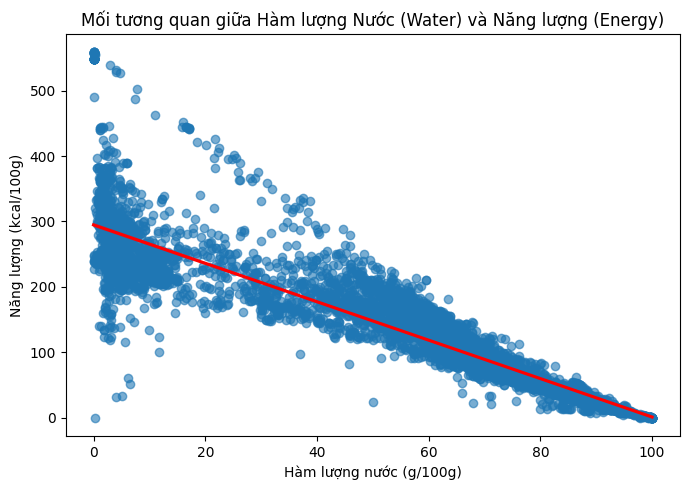

In [1290]:
# Lọc dữ liệu chỉ lấy Energy và Water
ndata_water = ndata[ndata['nutrient'].isin(['Energy', 'Water'])]

# Tạo bảng pivot để Energy và Water nằm cùng hàng
pivot_water = ndata_water.pivot_table(
    index=['food', 'fgroup'],
    columns='nutrient',
    values='value',
    aggfunc='mean'
).reset_index()

# Loại bỏ dòng thiếu dữ liệu
pivot_water = pivot_water.dropna(subset=['Energy', 'Water'])

# Nếu có dữ liệu ở đơn vị kJ, chuyển sang kcal
if 'units' in ndata.columns:
    if (ndata.loc[ndata['nutrient'] == 'Energy', 'units'] == 'kJ').any():
        pivot_water['Energy'] = pivot_water['Energy'] / 4.184

# Tính hệ số tương quan giữa Energy và Water
corr_value = pivot_water['Energy'].corr(pivot_water['Water'])
print(f"Hệ số tương quan giữa Water và Energy: {corr_value:.3f}")

# Vẽ biểu đồ scatter với đường hồi quy
plt.figure(figsize=(7, 5))
sns.regplot(
    data=pivot_water,
    x='Water',
    y='Energy',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)
plt.title('Mối tương quan giữa Hàm lượng Nước (Water) và Năng lượng (Energy)')
plt.xlabel('Hàm lượng nước (g/100g)')
plt.ylabel('Năng lượng (kcal/100g)')
plt.tight_layout()
plt.show()

Biểu đồ cho thấy mối tương quan nghịch khá rõ giữa hàm lượng nước và năng lượng. Thực phẩm có nhiều nước (như rau, trái cây, sữa, súp…) thường có mật độ năng lượng thấp, trong khi thực phẩm khô (như ngũ cốc,dầu, bánh nướng) chứa ít nước nhưng năng lượng cao hơn.

→ Kết quả phù hợp với nguyên lý dinh dưỡng: nước không cung cấp năng lượng, nên thực phẩm chứa nhiều nước sẽ có năng lượng thấp hơn trên mỗi 100g.